The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


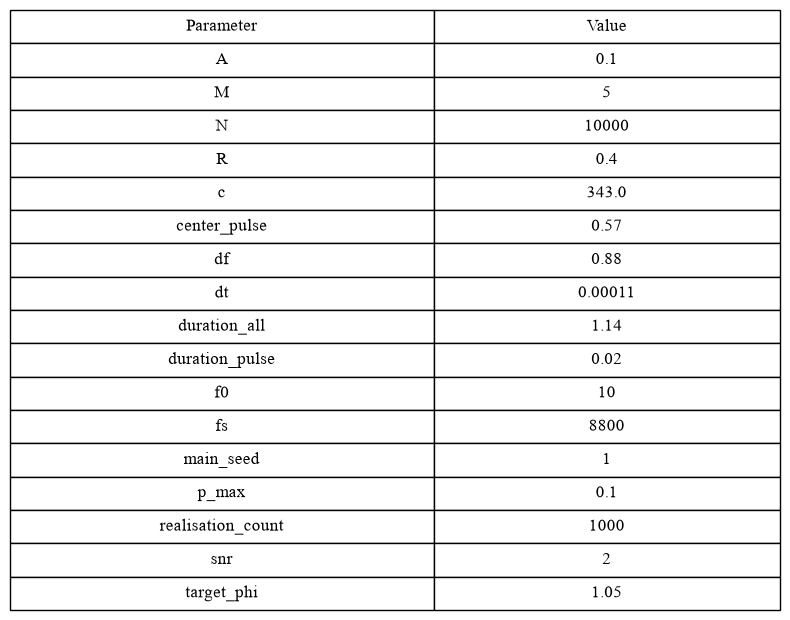

In [14]:
"""В данном модуле исследуется зависимость центральной частоты гармонического
сигнала от статистических характеристик. Сравниваются точная и приближённая модели.
Определяется область частот, в которой применима приближённая
модель"""

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
%load_ext autoreload
%autoreload 2

import numpy as np
import time
import src.experement as experement
import src.pseudospectrum as pseudospectrum
import src.configs.config as config
import src.signals as signals
import src.model as model
import src.configs.comon as comon
import src.plotting as plotting
import os
origin_config = config.init_rng()
sin_signal = signals.sinus
path = "attachment/images/report"
os.makedirs(path,exist_ok=True)
plotting.create_config_table(origin_config)

In [ ]:
conf1 = config.restart_rng(origin_config)
conf2 = config.restart_rng(origin_config)
start_time = time.perf_counter()
    

mean_bartlett_vs_f = experement.stat_vs_params(config_params=conf1,
                                   energy_func=pseudospectrum.approx_bartlett,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = config.FREQ_VALUES,
                                   stiring_func = model.calculate_stiring_matrix,
                                   stat_func = np.mean,
                                   is_CRN = False
                                   )
conf1 = config.restart_rng(origin_config)
conf2 = config.restart_rng(origin_config)

mean_bartlett_vs_f_complex = experement.stat_vs_params(config_params = conf2,
                                   energy_func = pseudospectrum.exact_bartlett,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = config.FREQ_VALUES,
                                   stiring_func = model.complex_stiring_matrix,
                                   stat_func = np.mean,
                                   is_CRN = False)

delta_var = np.abs(np.array(mean_bartlett_vs_f_complex) - np.array(mean_bartlett_vs_f))
end_time = time.perf_counter()

delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Signal frequency $f_0$, Hz', ylabel='$\\mathbb{E}[\\varepsilon]$, deg'>)

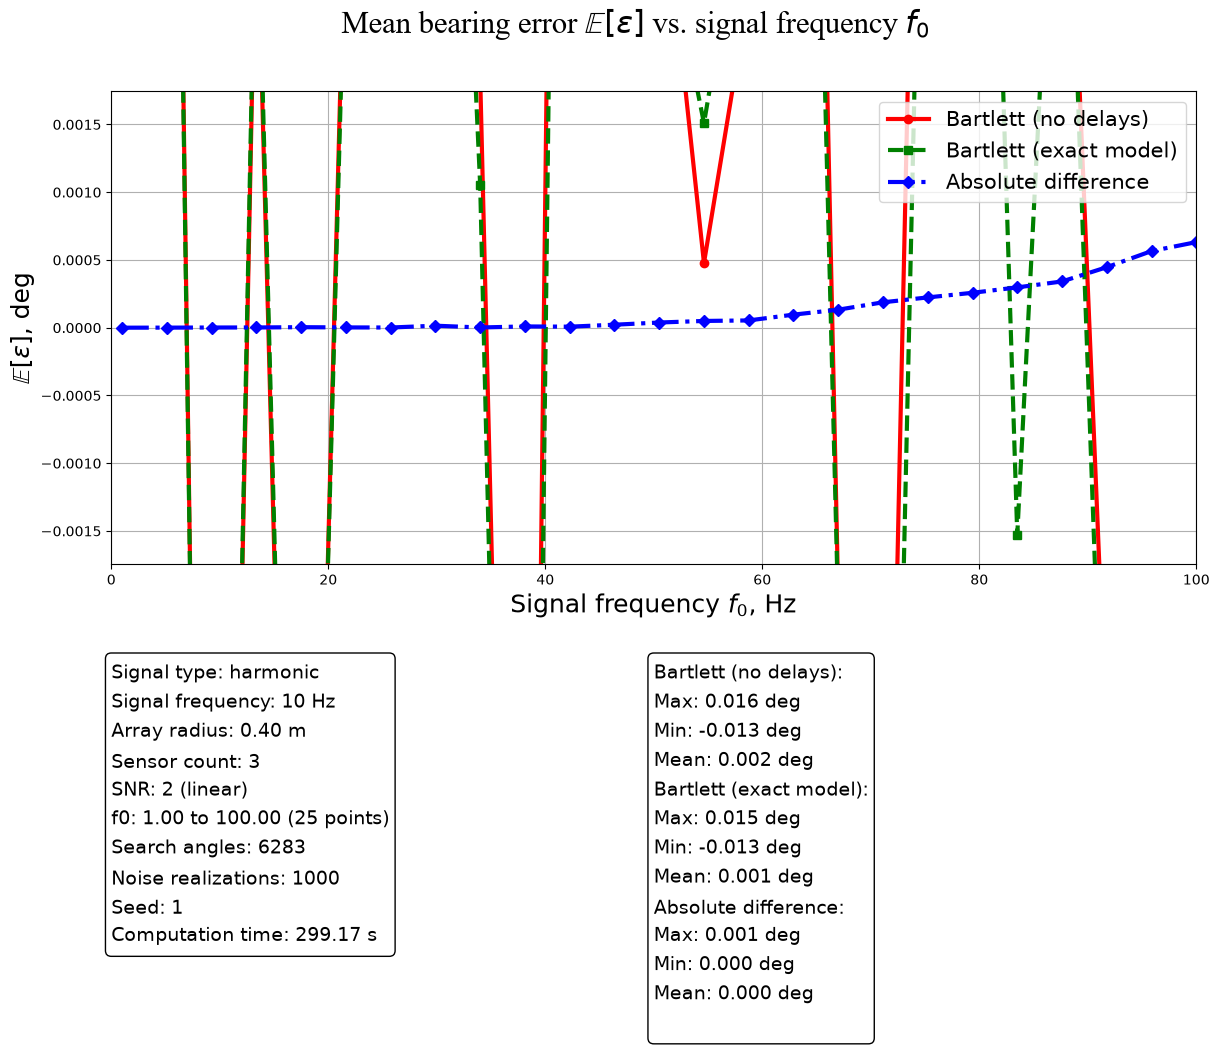

In [ ]:
plotting.plot_mean_vs_param(dict_values = {"Bartlett (no delays)": mean_bartlett_vs_f,
                                      "Bartlett (exact model)": mean_bartlett_vs_f_complex,
                                      "Absolute difference": delta_var},

                       config_params = origin_config.copy(),
                       parametr_values = config.FREQ_VALUES,
                       parametr_name = "f0",
                       delta_time = delta_time,
                       ylim = (-0.1*comon.CONST_RADIAN, 0.1*comon.CONST_RADIAN),
                       xlim = (0,100),
                       type_signal = "garmonic"
                       )

In [ ]:
conf1 = config.restart_rng(origin_config)
conf2 = config.restart_rng(origin_config)
start_time = time.perf_counter()


var_bartlett_vs_f = experement.stat_vs_params(config_params=conf1,
                                   energy_func=pseudospectrum.approx_bartlett,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = config.FREQ_VALUES,
                                   stiring_func = model.calculate_stiring_matrix,
                                   stat_func = experement.calculate_variance,
                                   is_CRN = True
                                   )

conf1 = config.restart_rng(origin_config)
conf2 = config.restart_rng(origin_config)

var_bartlett_vs_f_complex = experement.stat_vs_params(config_params = conf2,
                                   energy_func = pseudospectrum.exact_bartlett,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = config.FREQ_VALUES,
                                   stiring_func = model.complex_stiring_matrix,
                                   stat_func = experement.calculate_variance,
                                   is_CRN = True)

delta_var = np.abs(np.array(var_bartlett_vs_f_complex) - np.array(var_bartlett_vs_f))
end_time = time.perf_counter()

delta_time = end_time - start_time

46.375


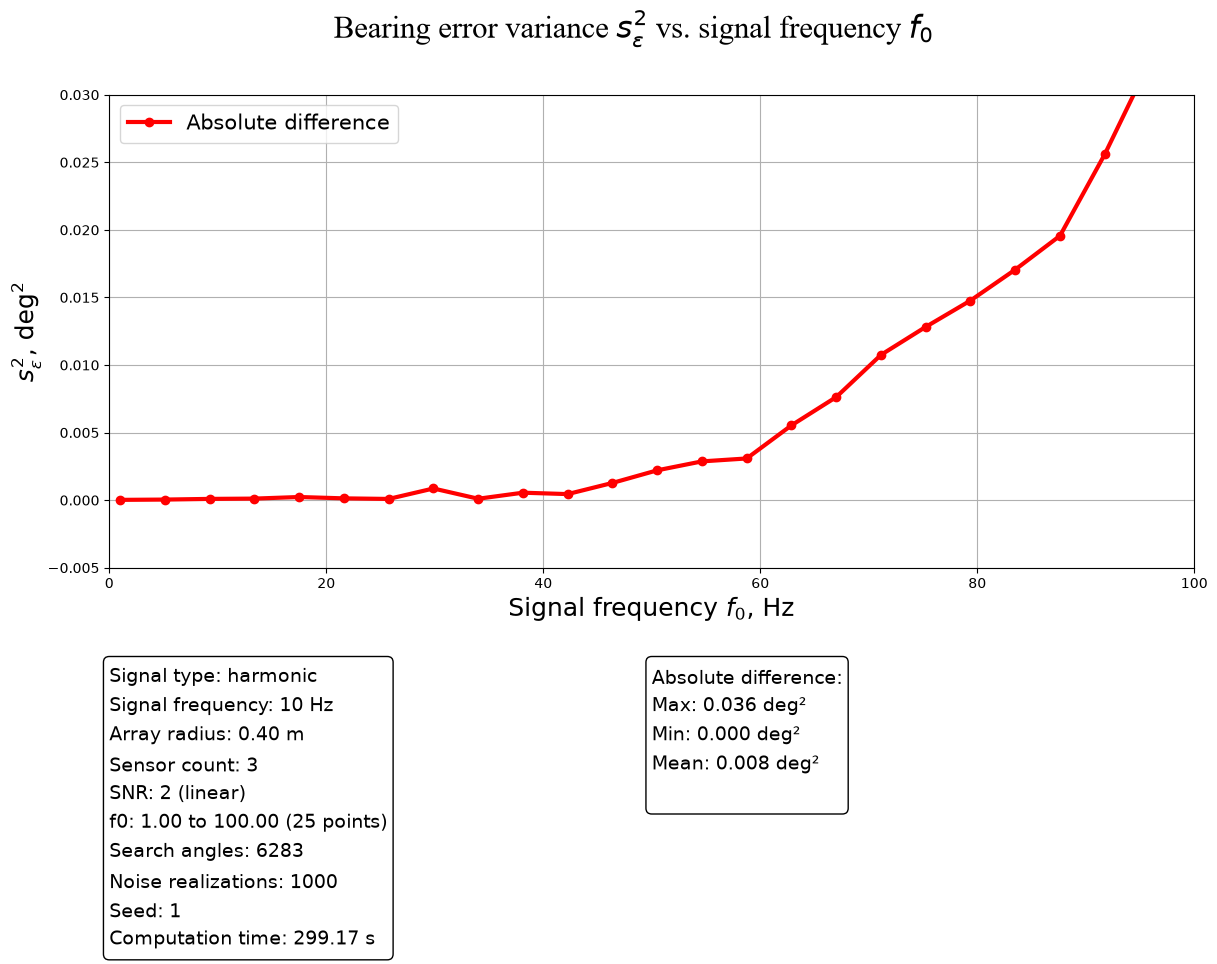

In [ ]:
plotting.plot_variance_vs_param(dict_values = {#"Bartlett (no delays)": var_bartlett_vs_f,
                                      #"Bartlett (exact model)": var_bartlett_vs_f_complex,
                                      "Absolute difference": delta_var},

                       config_params = origin_config.copy(),
                       parametr_values = config.FREQ_VALUES,
                       parametr_name = "f0",
                       delta_time = delta_time,
                       ylim = (-0.005*comon.CONST_RADIAN, 0.03*comon.CONST_RADIAN),
                       xlim = (0, 100),
                       type_signal = "garmonic")
print(config.FREQ_VALUES[11])